# Data Quality Report
Systematic profiling and cleaning of the three source datasets.
All fixes are implemented in `src/clean.py`. This notebook documents what was found,
what was fixed, and what the data looks like after cleaning.

In [1]:
import sys
from pathlib import Path

     
project_root = Path().resolve().parent
sys.path.insert(0, str(project_root / 'src'))



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from load     import load_sales, load_buyers, load_vendor_files
from clean    import clean_sales, clean_buyers, clean_vendors, verify_sku_match_rate
from checks   import run_all_checks
from features import build_line_items, build_orders

FIGURES_DIR = project_root / 'outputs' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='muted')
print('imports ok')

imports ok


## 1. Raw Data — Before Cleaning
Shapes and basic column inspection before any transforms are applied.

In [2]:
sales_raw   = load_sales()
buyers_raw  = load_buyers()
vendors_raw = load_vendor_files()

print('=== RAW SHAPES ===')
print(f'sales:   {sales_raw.shape}')
print(f'buyers:  {buyers_raw.shape}')
print(f'vendors: {vendors_raw.shape}')
print()
print('=== SALES COLUMNS ===')
print(sales_raw.dtypes)
print()
print('=== ORDER STATUS VALUES (raw) ===')
print(sales_raw['order_status'].value_counts())

=== RAW SHAPES ===
sales:   (376004, 6)
buyers:  (52500, 14)
vendors: (1037, 13)

=== SALES COLUMNS ===
order_id          object
buyer_id          object
sku_id            object
quantity          object
order_datetime    object
order_status      object
dtype: object

=== ORDER STATUS VALUES (raw) ===
order_status
Delivered     357225
Cancelled      11288
Deliverred      3714
Name: count, dtype: int64


## 2. Sales Cleaning
Issues found and fixed in `sales.csv`.

In [3]:
sales = clean_sales(sales_raw)

print('==== AFTER CLEANING====')
     
print(f'rows before: {len(sales_raw):,}')
print(f'rows after:  {len(sales):,}')
print(f'rows removed: {len(sales_raw) - len(sales):,}')
print()
print('=== ORDER STATUS VALUES (clean) ===')
print(sales['order_status'].value_counts())
print()
print('===DATETIME FORMATS===')
print(f'rows with time component:  {sales["datetime_has_time"].sum():,}')
print(f'rows date-only (no hour):  {(~sales["datetime_has_time"]).sum():,}')
print()
print('=== QUANTITY ===')
print(f'valid quantities:   {sales["quantity_is_valid"].sum():,}')
print(f'invalid quantities: {(~sales["quantity_is_valid"]).sum():,}')

  [sales] dropped 24,878 exact duplicate rows
  [sales] 394 rows flagged quantity_is_valid=False (null or > 50)
  [sales] dropped 322 rows with null buyer_id
==== AFTER CLEANING====
rows before: 376,004
rows after:  350,804
rows removed: 25,200

=== ORDER STATUS VALUES (clean) ===
order_status
Delivered    336723
Cancelled     10501
Name: count, dtype: int64

===DATETIME FORMATS===
rows with time component:  346,262
rows date-only (no hour):  4,542

=== QUANTITY ===
valid quantities:   350,410
invalid quantities: 394


## 3. Buyers Cleaning
Issues fixed from `buyer.csv`.

In [4]:
buyers = clean_buyers(buyers_raw)

print('=== AFTER CLEANING ===')
print(f'rows before: {len(buyers_raw):,}')
print(f'rows after:  {len(buyers):,}')
print(f'rows removed: {len(buyers_raw) - len(buyers):,}')
print()
print('=== NULL RATES AFTER CLEANING ===')
null_rates = buyers.isna().mean().sort_values(ascending=False)
print(null_rates[null_rates > 0].apply(lambda x: f'{x:.2%}'))
print()
     
print('=== CUSTOMER GROUP DISTRIBUTION ===')
print(buyers['customer_group'].value_counts())

  [buyers] dropped 2,634 rows with null buyer_id
  [buyers] dropped 2,366 exact duplicate rows
  [buyers] deduped to one row per buyer_id (0 additional rows removed)
  [buyers] null region after imputation:   0
  [buyers] null timezone after imputation: 0
=== AFTER CLEANING ===
rows before: 52,500
rows after:  47,500
rows removed: 5,000

=== NULL RATES AFTER CLEANING ===
signup_date    2.20%
is_referred    1.00%
dtype: object

=== CUSTOMER GROUP DISTRIBUTION ===
customer_group
Dormant       23716
Regular        9512
Occasional     7148
Frequent       5694
VIP            1430
Name: count, dtype: int64


## 4. Vendors Cleaning + SKU Match Rate
Biggest issue: NKDLI.csv stored key columns in lowercase, silently dropping 46 SKUs from the join.

In [5]:
vendors = clean_vendors(vendors_raw)

print('=== VENDOR CATALOG ===')
print(f'total SKUs: {len(vendors):,}')
print(f'unique vendors: {vendors["vendor"].nunique()}')
print()

print('=== SKU MATCH RATE ===')
rate = verify_sku_match_rate(sales, vendors, label='post-clean')
print()

print('=== PROFIT MARGIN SUMMARY ===')
     
pm = vendors['profit_margin'].dropna()
print(f'min:      {pm.min():.4f}')
print(f'max:      {pm.max():.4f}')
print(f'negative: {(pm < 0).sum()} SKUs (loss-leaders)')
print(f'positive: {(pm >= 0).sum()} SKUs')

  [vendors] 111 negative margin rows (loss-leaders) in: JDTOJ.csv, KWOXE.csv, NKDLI.csv, PQYYY.csv, SOPAJ.csv, TAAFL.csv, WQEPS.csv
=== VENDOR CATALOG ===
total SKUs: 1,037
unique vendors: 11

=== SKU MATCH RATE ===
  [sku_match [post-clean]] 1,037 / 1,037 sales SKUs matched (100.0%)

=== PROFIT MARGIN SUMMARY ===
min:      -0.0444
max:      0.9271
negative: 111 SKUs (loss-leaders)
positive: 900 SKUs


## 5. Profit Margin Distribution
The distribution is bimodal -- two natural pricing tiers exist across all vendors.
Loss-leader products (margin < 0) are shown separately on the left panel.

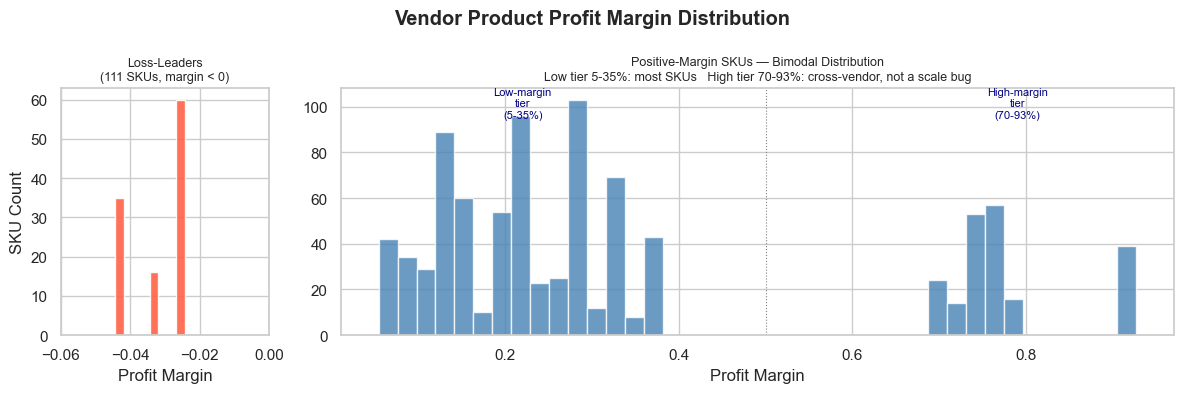

saved: dq_profit_margin_dist.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4),
                         gridspec_kw={'width_ratios': [1, 4]})

ax_neg = axes[0]
neg_m = vendors.loc[vendors['profit_margin_is_neg'], 'profit_margin']
ax_neg.hist(neg_m, bins=8, color='tomato', alpha=0.9)
ax_neg.set_xlim(-0.06, 0.0)
ax_neg.set_xlabel('Profit Margin')
ax_neg.set_ylabel('SKU Count')
ax_neg.set_title(f'Loss-Leaders\n({len(neg_m)} SKUs, margin < 0)', fontsize=9)
ax_neg.axvline(0, color='black', lw=0.8, ls='--')

ax_pos = axes[1]
pos_m = vendors.loc[~vendors['profit_margin_is_neg'], 'profit_margin']
ax_pos.hist(pos_m, bins=40, color='steelblue', alpha=0.8)
ax_pos.set_xlabel('Profit Margin')
ax_pos.set_title(
    'Positive-Margin SKUs — Bimodal Distribution\n'
    'Low tier 5-35%: most SKUs   High tier 70-93%: cross-vendor, not a scale bug',
    fontsize=9
)
ax_pos.axvline(0.5, color='gray', lw=0.8, ls=':')
ax_pos.text(0.22, 95, 'Low-margin\ntier\n(5-35%)',
            fontsize=8, ha='center', color='navy')
ax_pos.text(0.79, 95, 'High-margin\ntier\n(70-93%)',
            fontsize=8, ha='center', color='navy')

fig.suptitle('Vendor Product Profit Margin Distribution', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'dq_profit_margin_dist.png', dpi=150, bbox_inches='tight')
plt.show()
print('saved: dq_profit_margin_dist.png')

## 6. Pipeline Checks
Runing all 27 assertions to confirm the cleaned data meets every expectation.

In [7]:
line_items = build_line_items(sales, vendors, buyers)
orders     = build_orders(line_items)
run_all_checks(sales, buyers, vendors, line_items, orders)


=== running pipeline checks ===
[checks] sales
  ✓ row count > 300k after dedup
  ✓ no null buyer_id rows remain
  ✓ order_status typo Deliverred fully corrected
  ✓ quantity_is_valid rate > 99.8%
  ✓ parsed datetime coverage > 300k rows
[checks] buyers
  ✓ buyer row count > 40k after cleaning
  ✓ one row per buyer_id
  ✓ no null buyer_id rows remain
  ✓ null region rate < 5% after imputation
  ✓ null timezone rate < 5% after imputation
[checks] vendors
  ✓ all rows have a sku_id
  ✓ no duplicate sku_ids in vendor catalog
  ✓ profit_margin max < 1.5 -- catches un-fixed 0-100 scale
  ✓ all non-null margins in [-1, 1]
  ✓ vendor catalog has >= 1000 SKUs
[checks] sku match rate
  ✓ SKU match rate >= 99.9%
[checks] line_items
  ✓ eligible_revenue column exists
  ✓ eligible_profit column exists
  ✓ no negative eligible_revenue values
  ✓ timezone conversion produced order_datetime_central
  ✓ order_datetime_central coverage > 90%
  ✓ is_black_friday column exists
[checks] orders
  ✓ one ro